In [1]:
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
import pandas as pd
from sklearn.impute import SimpleImputer
import numpy as np
from sklearn.preprocessing import LabelEncoder, OneHotEncoder
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import accuracy_score, r2_score, root_mean_squared_error
from sklearn.preprocessing import OneHotEncoder
from sklearn.tree import plot_tree
from sklearn.model_selection import RandomizedSearchCV

In [2]:
df = pd.read_csv(r"C:\Users\kashv\Desktop\Delhi_UHI_Project\Data\Processed\cleaned_dataset.csv")
df.head()
df = df.drop(columns=["LULC"])

In [3]:
# One hot encoding
ohe = OneHotEncoder(drop="first", sparse_output=False, handle_unknown="ignore")
encoded = ohe.fit_transform(df[["LULC_Name"]])

encoded_df = pd.DataFrame(
    encoded,
    columns=ohe.get_feature_names_out(["LULC_Name"]),
    index = df.index
)

df = pd.concat([df.drop(columns=["LULC_Name"]),encoded_df], axis=1)

In [4]:
df.columns

Index(['Latitude', 'Longitude', 'AirTemp', 'DistanceToWater', 'Elevation',
       'Humidity', 'LST', 'MNDWI', 'NDBI', 'NDVI', 'Population', 'Slope',
       'WindSpeed', 'LULC_Name_Built Area', 'LULC_Name_Crops',
       'LULC_Name_Flooded Vegetation', 'LULC_Name_Grass', 'LULC_Name_Shrub',
       'LULC_Name_Trees', 'LULC_Name_Water'],
      dtype='object')

In [5]:
X = df.drop(columns=["LST"])
y = df["LST"]

In [6]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=43
)

In [7]:
rf = RandomForestRegressor(
    random_state=43,
    oob_score=True
)

rf.fit(X_train, y_train)

,n_estimators,100
,criterion,'squared_error'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,1.0
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,True


In [8]:
y_pred_train = rf.predict(X_train)
y_pred_test = rf.predict(X_test)

print(f"oob_score of data = {rf.oob_score_}")

print(f"MSE of training data = {root_mean_squared_error(y_train, y_pred_train)}")
print(f"MSE of testing data = {root_mean_squared_error(y_test, y_pred_test)}")

print(f"r2_score of training data = {r2_score(y_train, y_pred_train)}")
print(f"r2_score of testing data = {r2_score(y_test, y_pred_test)}")

oob_score of data = 0.8330986508580941
MSE of training data = 0.5172897511391797
MSE of testing data = 1.355638437110324
r2_score of training data = 0.976878073371027
r2_score of testing data = 0.8368169662192763


# Hyperparameter tuning to reduce overfitting

In [9]:
# param_grid = {
#     "n_estimators" : [100,200,300,400,500],
#     "max_depth" : [10,15,20,25,30],
#     "min_samples_split" : [5,10,15,20,25],
#     "min_samples_leaf" : [1,2,3,4,5]
# }

# random_search = RandomizedSearchCV(
#     rf,
#     param_grid,
#     scoring="r2",
#     n_iter=30,
#     cv=5,
#     n_jobs=-1
# )

# random_search.fit(X_train, y_train)
# best_r2_score = random_search.best_score_
# best_param = random_search.best_params_

In [10]:
# print(best_r2_score)
# print(best_param)

In [11]:
rf2 = RandomForestRegressor(
    random_state=43,
    oob_score=True,
    n_estimators=300,
    min_samples_split=10,
    min_samples_leaf=3,
    max_depth=15
)

rf2.fit(X_train, y_train)

y_pred_train = rf2.predict(X_train)
y_pred_test = rf2.predict(X_test)

print(f"oob_score of data = {rf2.oob_score_}")

print(f"MSE of training data = {root_mean_squared_error(y_train, y_pred_train)}")
print(f"MSE of testing data = {root_mean_squared_error(y_test, y_pred_test)}")

print(f"r2_score of training data = {r2_score(y_train, y_pred_train)}")
print(f"r2_score of testing data = {r2_score(y_test, y_pred_test)}")

oob_score of data = 0.832022600022303
MSE of training data = 0.8816317246338039
MSE of testing data = 1.3550161551615962
r2_score of training data = 0.9328369067591508
r2_score of testing data = 0.8369667444301365


In [12]:
importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": rf2.feature_importances_*100
})

importance = importance.sort_values(by="Importance", ascending=False)

importance

,Feature,Importance
7,NDBI,64.272911
1,Longitude,15.277795
0,Latitude,4.204040
3,DistanceToWater,3.555963
9,Population,3.512147
6,MNDWI,3.134307
8,NDVI,1.815489
4,Elevation,1.274246
10,Slope,0.998875
12,LULC_Name_Built Area,0.568417


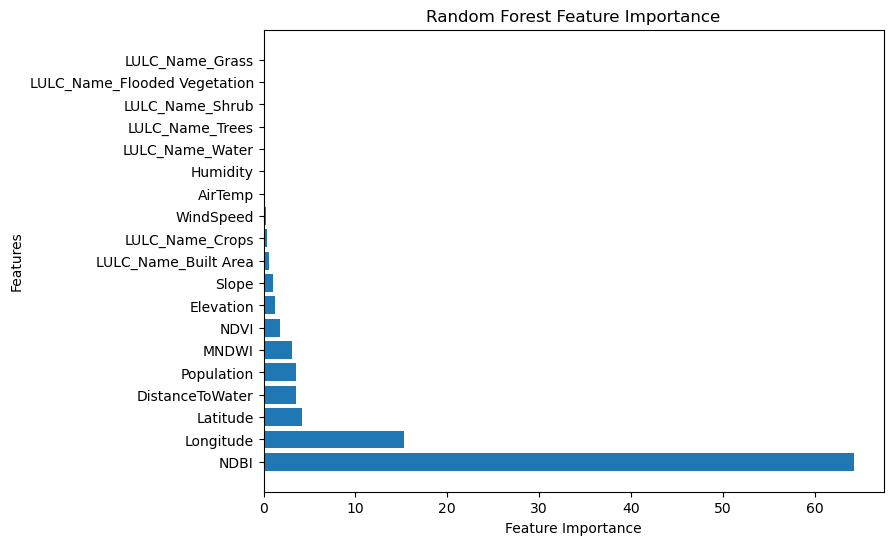

In [13]:
plt.figure(figsize=(8,6))

plt.barh(
    importance["Feature"],
    importance["Importance"]
)

plt.xlabel("Feature Importance")
plt.ylabel("Features")
plt.title("Random Forest Feature Importance")

plt.show()

In [14]:
print(df["AirTemp"].describe())
print(df["AirTemp"].nunique())

count    9989.000000
mean       32.511031
std         0.203881
min        31.983528
25%        32.366906
50%        32.509743
75%        32.641314
max        32.992381
Name: AirTemp, dtype: float64
26


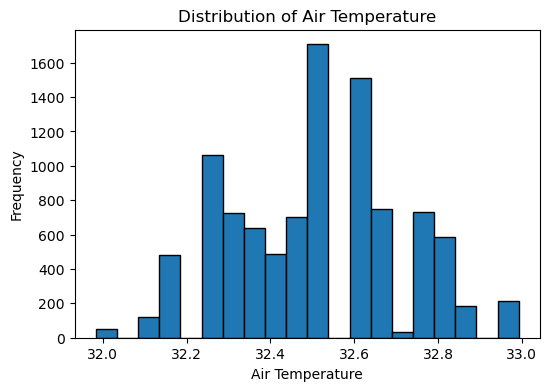

In [15]:
plt.figure(figsize=(6,4))
plt.hist(df["AirTemp"], bins=20, edgecolor="black")
plt.xlabel("Air Temperature")
plt.ylabel("Frequency")
plt.title("Distribution of Air Temperature")
plt.show()